# Imports

In [5]:
from utils import *

import pandas as pd
import numpy as np
from sklearn.mixture import GaussianMixture
from scipy.stats import norm

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Setup

In [3]:
##############################
# Read Dataset into Dataframe
##############################

# path to cleaned dataset
clean_path = r'../data/mnz_cleaned.csv'

# structural zones for iteration
structural_zones = ['MDHSZ', 'GS', 'CBSZ', 'CMZI']

# output path for choosing components
component_output_path = [f"../results/gmm_clusters_{zone}.png" for zone in structural_zones]

# output path for interpretation
output_path = r'../results/gmm_interpretation.png'


##### read into df...
df = pd.read_csv(clean_path)
df.sort_values('error', inplace=True)
df.reset_index(inplace=True)


df.head()

,level_0,index,sample,zone,mnz,texture,texture_chem,n,age,error,...,Er2O3,Tm2O3,Yb2O3,SO3,PbO,percent,lree,HREE,garnet,cordierite
0,0,8,EB14-001,CMZI,m28,overgrowth,Y depleted overgrowth,6.0,348.85,0.683097,...,0.034439,0.069372,0.009740,0.018835,0.096939,0.195814,59.804756,1.359903,1,0
1,2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.00,0.784962,...,0.014718,0.009812,0.009812,0.020605,0.079477,0.220495,61.972776,1.588568,1,0
2,1,111,P14-003-2B,MDHSZ,m50,core,Th enriched core,5.0,307.14,0.789124,...,0.009937,0.019969,0.009937,0.018184,0.132687,0.256926,57.520514,0.670830,1,0
3,3,114,M1605-2-L3,MDHSZ,m4,rim,Y depleted rim,5.0,298.70,1.346540,...,0.009748,0.009748,0.009748,0.016339,0.082968,0.450800,61.526147,1.376610,1,0
4,4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.24,1.408622,...,0.009641,0.060215,0.009641,0.014777,0.085454,0.398772,60.699177,1.389823,1,1


# Gaussian Mixture Model

## Determine number of Components

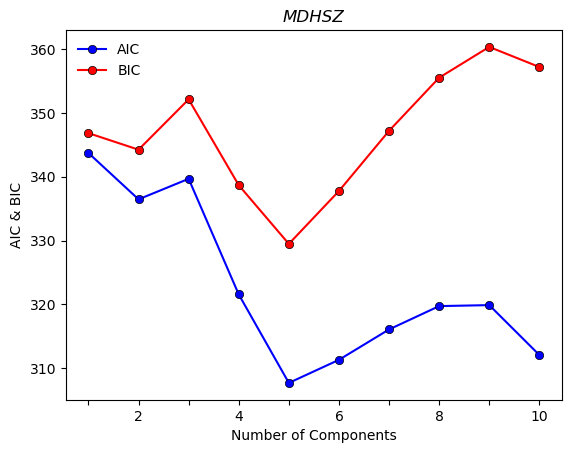

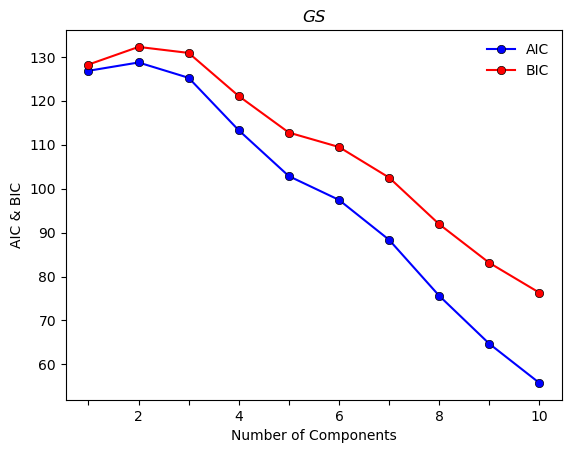

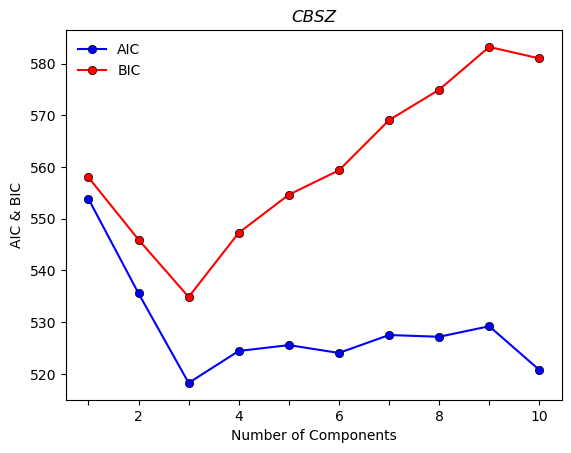

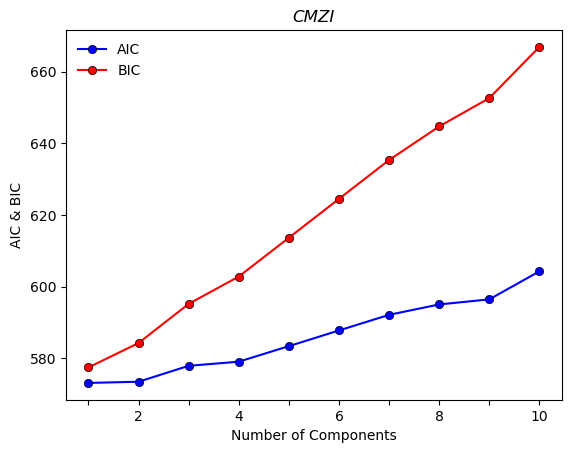

In [4]:


for idx, zone in enumerate(structural_zones):

    df_subset = df[df['zone']==zone].copy()
    ages = df_subset['age'].to_numpy().reshape(-1,1)

    aic = []
    bic = []
    
    for k in np.arange(1, 11, 1):

        gm = GaussianMixture(n_components=k, covariance_type="full", n_init=10, random_state=111).fit(ages)
        aic.append(gm.aic(ages))
        bic.append(gm.bic(ages))
    
    fig, ax = plt.subplots()
    ax.plot(np.arange(1, 11, 1), aic, color='blue', marker='o', markeredgecolor='k', markeredgewidth=0.5, label='AIC')
    # ax2 = ax.twinx()
    ax.plot(np.arange(1, 11, 1), bic, color='red', marker='o', markeredgecolor='k', markeredgewidth=0.5, label='BIC')

    ax.legend(loc='best', frameon=False)
    ax.set_xticks(np.arange(1,11,1))
    ax.set_xticklabels(str(i) if i%2==0 else '' for i in np.arange(1,11,1))
    ax.set_xlabel('Number of Components')
    ax.set_ylabel('AIC & BIC')
    ax.set_title(zone, style='italic')

    plt.savefig(component_output_path[idx], dpi=300, pad_inches=0, bbox_inches='tight')
    plt.show()




## Final Cluster Labels

In [ ]:
# fig, ax = plt.subplots(nrows=1, ncols=4, sharey=True, figsize=(10,6))
# plt.subplots_adjust(wspace=0)

# # # define number of components from above
# # zone_clusters = {'MDHSZ': 5, 
# #                  'GS': 5, 
# #                  'CBSZ': 3, 
# #                  'CMZI': 3}

# # define colors for plots
# # k_colors = ['#BB6653', '#E1AA36', '#BCA88D', '#239BA7', '#415E72', '#3E3F29']

# # initialize dictionary to hold weighted mean stats
# all_stats = {}

# # create timeline array
# timeline = np.linspace(200, 500, 1000)

# ##### iterate through structural zones...
# for idx, zone in enumerate(zone_clusters.keys()):

#     # initialize zone entry in dictionary
#     all_stats[zone] = {}

#     # create subset df for zone of interest
#     df_subset = df[df['zone']==zone].copy()

#     # get array of ages and errors for GMM model (shape: N x 1)
#     all_ages = df_subset['age'].to_numpy().reshape(-1,1)
#     all_errors = df_subset['error'].to_numpy().reshape(-1,1)

#     # fit GMM using chosen components
#     gm = GaussianMixture(n_components=zone_clusters[zone], covariance_type="full", n_init=10, random_state=111).fit(all_ages)

#     # extract GMM stats...
#     means = gm.means_.ravel()                   # component means
#     stds  = np.sqrt(gm.covariances_).ravel()    # component standard deviations
#     weights = gm.weights_.ravel()               # component weights
    
#     # order stats by component mean age (young→old) for consistent colors
#     order = np.argsort(means)
#     means, stds, weights = means[order], stds[order], weights[order]

#     # get component PDFs...
#     components = []
#     stds_plot = np.clip(stds, 0.5, None)
#     for mu, sd, w in zip(means, stds_plot, weights):
#         components.append(w * norm.pdf(timeline, loc=mu, scale=sd))

#     # responsibilities and labels, remapped to the ordered component index
#     R = gm.predict_proba(all_ages)[:, order]
#     labels = R.argmax(axis=1)
#     df_subset['labels'] = labels

#     df_subset.sort_values(['labels', 'error'], inplace=True)
#     df_subset.reset_index(drop=True, inplace=True)

#     # keep track of maximum density to set xlim in plots...
#     density_max = 0.0
#     ax2_density_max = 0.0

#     # plot component PDFs...
#     ax2 = ax[idx].twiny()
#     for j, density in enumerate(components):
#         ax2_density_max = max(ax2_density_max, density.max())
#         ax2.fill_between(density, timeline, color=k_colors[j], linewidth=0.5, edgecolor='k', alpha=0.4, zorder=2)


#     ##### iterate through components...
#     for k in df_subset['labels'].unique():
        
#         # get ages, errors, & weighted mean stats for component of interest...
#         ages = df_subset.loc[df_subset['labels'] == k, 'age'].to_numpy().reshape(-1,1)
#         errors = df_subset.loc[df_subset['labels'] == k, 'error'].to_numpy().reshape(-1,1)
#         stats = cluster_stats(ages, errors, two_sigma=False)
#         all_stats[zone][k] = stats
        

#         ##### plot individual sample gaussian curves...
#         for _, row in df_subset[df_subset['labels'] == k].iterrows():
#             mean = row['age']
#             error = row['error']
#             k_label = row['labels']

#             # get age range for calculating sample PDF
#             age_range = np.linspace(mean - 4 * error, mean + 4 * error, 1000)

#             # get density of PDF for sample
#             density = norm.pdf(age_range, mean, error)

#             # update density max with highest value (or keep old value)
#             density_max = max(density_max, density.max())

#             # plot PDF curves
#             ax[idx].fill_between(density, age_range, alpha=1, color=k_colors[k_label], linewidth=0.5, edgecolor='k')
        
#         # construct label with weighted mean stats
#         label = f"Component {k} (n={int(stats['n'])})\n{round(stats['mean'])} +/- {round(stats['ci95_halfwidth'], 2)}\nMSWD = {round(stats['mswd'],2)}"

#         # plot weighted mean line
#         ax[idx].axhline(y=stats['mean'], xmin=0, xmax=1, color=k_colors[k], linewidth=2, linestyle='--', zorder=2, label=label)

#         # plot CI ribbon around mean (if at least 3 samples)...
#         # if stats['n'] >= 3:
#         #     ax[idx].fill_between(x=np.linspace(0,2,100), y1=stats['mean'] - stats['ci95_halfwidth'], y2=stats['mean'] + stats['ci95_halfwidth'], color=k_colors[k_label], alpha=0.5, zorder=0.5)
#     ax[idx].legend(loc='upper left', bbox_to_anchor=(0,0), frameon=False)

        

#     ax2.set_xticks([])
#     ax2.set_xlim(0, ax2_density_max)
#     ax2.spines['top'].set_visible(False)

#     ax[idx].set_title(zone, style='italic', y=0.97)
#     ax[idx].set_xlim(0, density_max)

#     ax[idx].invert_yaxis()
#     ax2.invert_yaxis()


# ##### figure styling...
# for axes in ax:
#     # axes.set_xlim(0)
#     axes.set_ylim(210, 450)
#     axes.grid(visible=True, axis='y', linestyle='--', color='gray', linewidth=0.5)
#     axes.set_xticks([])
#     axes.spines['top'].set_visible(False)
#     axes.spines['bottom'].set_visible(False)

# ax[0].set_yticks(np.arange(220, 451, 10))
# ax[0].set_yticklabels([str(i) if i%20 == 0 else '' for i in np.arange(220, 451, 10)])
# ax[0].set_ylabel('Age (Ma)')

# plt.gca().invert_yaxis()
# plt.suptitle('GMM Age Components', y=0.94)
# # plt.savefig(r'../results/kmeans.png', bbox_inches="tight", pad_inches=0, dpi=300)
# plt.show()

In [ ]:
def gmm_processing(df, k, weights=None):
    ages = df['age'].to_numpy().reshape(-1,1)
    gmm = GaussianMixture(n_clusters=k, random_state=111, n_init='auto').fit(ages)
    pass

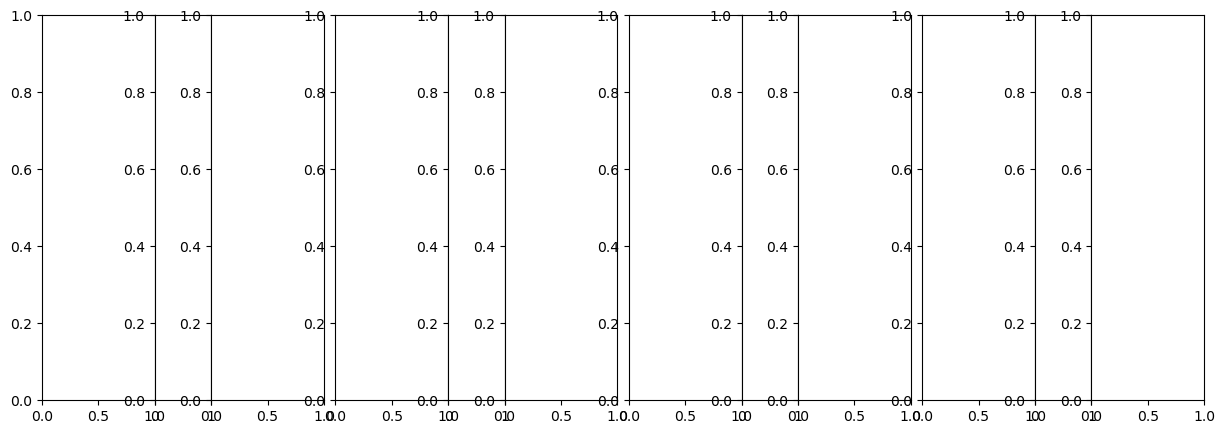

In [6]:
zone_clusters = {'MDHSZ': 5, 
                 'GS': 5, 
                 'CBSZ': 3, 
                 'CMZI': 4}


##### Plot figure...

fig = plt.figure(figsize=(15, 5))
width_ratios = [1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0]
gs = GridSpec(nrows=1, ncols=15, figure=fig, wspace=0, width_ratios=width_ratios)

# define axes - left triplet (A), spacer (hidden), right triplet (B)...
axA_1 = fig.add_subplot(gs[0, 0])
axA_2 = fig.add_subplot(gs[0, 1], sharey=axA_1)
axA_3 = fig.add_subplot(gs[0, 2], sharey=axA_1)
ax_sp1 = fig.add_subplot(gs[0, 3])                 # spacer
axB_1 = fig.add_subplot(gs[0, 4], sharey=axA_1)
axB_2 = fig.add_subplot(gs[0, 5], sharey=axA_1)
axB_3 = fig.add_subplot(gs[0, 6], sharey=axA_1)
ax_sp2 = fig.add_subplot(gs[0, 7])                 # spacer
axC_1 = fig.add_subplot(gs[0, 8], sharey=axA_1)
axC_2 = fig.add_subplot(gs[0, 9], sharey=axA_1)
axC_3 = fig.add_subplot(gs[0, 10], sharey=axA_1)
ax_sp3 = fig.add_subplot(gs[0, 11])                 # spacer
axD_1 = fig.add_subplot(gs[0, 12], sharey=axA_1)
axD_2 = fig.add_subplot(gs[0, 13], sharey=axA_1)
axD_3 = fig.add_subplot(gs[0, 14], sharey=axA_1)

# hide spacer axes...
ax_sp1.axis("off")
ax_sp2.axis("off")
ax_sp3.axis("off")



panel1_max = [0.0, 0.0, 0.0, 0.0]
panel3_max = [0.0, 0.0, 0.0, 0.0]

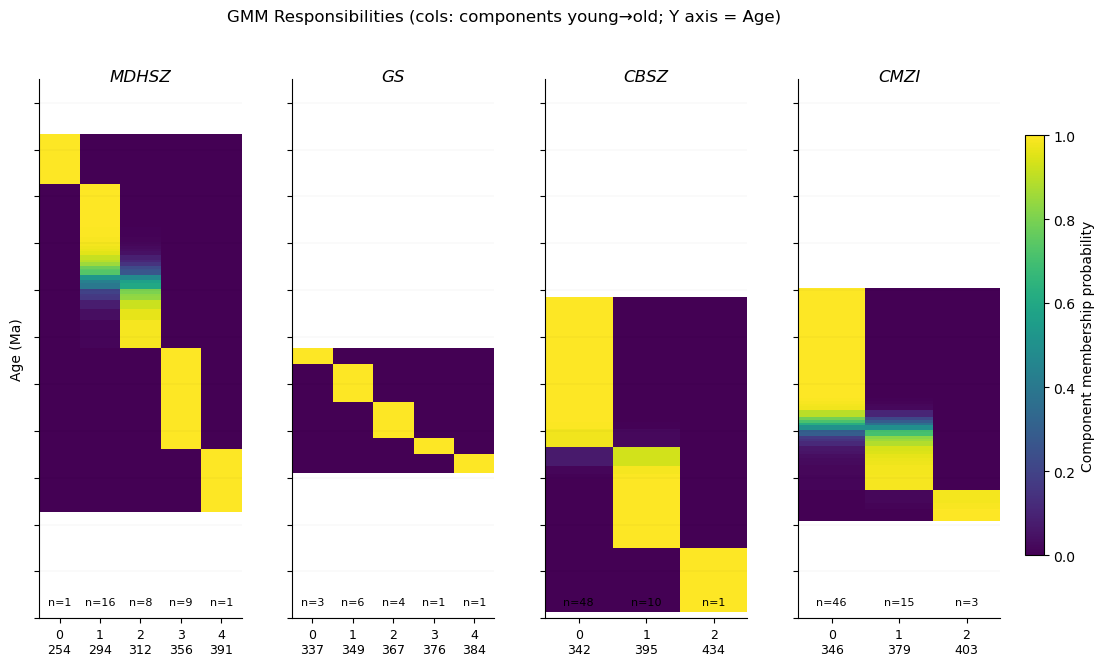

In [92]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# Expects:
# df with columns: ['zone', 'age', 'error']
# zone_clusters like: {'MDHSZ':5, 'GS':5, 'CBSZ':3, 'CMZI':3}

def _row_edges_from_sorted_ages(ages_sorted):
    """
    Build strictly increasing y-edges for pcolormesh so that each row spans
    the midpoint between adjacent sorted ages. This makes the vertical axis = Age (Ma).
    """
    ages_sorted = np.asarray(ages_sorted, dtype=float)
    n = ages_sorted.size
    if n == 1:
        # Single row: give it a small thickness (±0.5 Ma)
        return np.array([ages_sorted[0] - 0.5, ages_sorted[0] + 0.5])

    mids = 0.5 * (ages_sorted[:-1] + ages_sorted[1:])
    y_edges = np.empty(n + 1, dtype=float)
    y_edges[1:-1] = mids
    # extrapolate first/last edges
    y_edges[0]  = ages_sorted[0]  - (mids[0] - ages_sorted[0])
    y_edges[-1] = ages_sorted[-1] + (ages_sorted[-1] - mids[-1])

    # enforce strict monotonicity (guard against identical ages)
    eps = 1e-6
    for i in range(len(y_edges) - 1):
        if y_edges[i+1] <= y_edges[i]:
            y_edges[i+1] = y_edges[i] + eps
    return y_edges

def plot_gmm_responsibilities_heatmaps(df, zone_clusters, y_min=220, y_max=450, random_state=111):
    zones = list(zone_clusters.keys())
    ncols = len(zones)
    fig, axes = plt.subplots(1, ncols, figsize=(3.1*ncols, 7), sharey=True)

    if ncols == 1:
        axes = [axes]

    norm = Normalize(vmin=0.0, vmax=1.0)
    cmap = 'viridis'
    sm = ScalarMappable(norm=norm, cmap=cmap)  # for shared colorbar

    for c, zone in enumerate(zones):
        ax = axes[c]
        dfz = df[df['zone'] == zone].copy()

        ax.set_title(zone, style='italic', y=0.98)

        if dfz.empty:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)
            ax.set_xlim(-0.5, 0.5)
            ax.set_ylim(y_max, y_min)  # inverted (older at top)
            continue

        ages = dfz['age'].to_numpy().reshape(-1, 1)
        K = int(zone_clusters[zone])

        # Fit GMM and order components by mean age (young→old)
        gm = GaussianMixture(n_components=K, covariance_type="full", n_init=10, random_state=random_state).fit(ages)
        means = gm.means_.ravel()
        order = np.argsort(means)
        means = means[order]

        # Responsibilities aligned to ordered components
        R = gm.predict_proba(ages)[:, order]            # (N x K)
        hard = R.argmax(axis=1)

        # Sort rows by measured age (young→old)
        row_order = np.argsort(ages.ravel())
        ages_sorted = ages.ravel()[row_order]
        R_sorted = R[row_order, :]

        # Build y-edges from ages (vertical axis = Age)
        y_edges = _row_edges_from_sorted_ages(ages_sorted)

        # Build x-edges: K columns from 0..K
        x_edges = np.arange(K + 1)

        # pcolormesh expects Z shape (Ny, Nx) where Ny=len(y_edges)-1, Nx=len(x_edges)-1
        # Use origin='lower' so larger ages plot higher; then invert axis to match your style
        pc = ax.pcolormesh(x_edges, y_edges, R_sorted, cmap=cmap, norm=norm, shading='flat')

        # X ticks at cell centers with component mean ages
        ax.set_xticks(np.arange(K) + 0.5)
        ax.set_xticklabels([f"{j}\n{m:.0f}" for j, m in enumerate(means)], fontsize=9)

        # Y = Age axis (shared across panels)
        ax.set_ylim(y_max, y_min)  # invert so older (larger Ma) at top
        if c == 0:
            ax.set_ylabel("Age (Ma)")
            # full ticks every 20 Ma
            ax.set_yticks(np.arange(y_max, y_min-1, -20))
            ax.set_yticklabels([str(v) for v in np.arange(y_max, y_min-1, -20)])
        else:
            ax.set_yticks(np.arange(y_max, y_min-1, -20))
            ax.set_yticklabels([])

        # light horizontal grid for readability
        for y in np.arange(y_max, y_min-1, -20):
            ax.axhline(y, color='k', lw=0.2, alpha=0.15, zorder=3)

        # tidy frame
        ax.set_xlim(0, K)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        # annotate per-component n (optional; counts from hard labels)
        for j in range(K):
            ax.text(j + 0.5, y_max + (y_min - y_max)*0.02, f"n={np.sum(hard==j)}",
                    ha='center', va='bottom', fontsize=8)

    # Shared colorbar
    cax = fig.add_axes([0.92, 0.2, 0.015, 0.6])
    cb = fig.colorbar(sm, cax=cax)
    cb.set_label('Component membership probability', rotation=90)

    plt.subplots_adjust(wspace=0.25, right=0.90)
    plt.suptitle('GMM Responsibilities (cols: components young→old; Y axis = Age)', y=0.98)
    plt.show()

# ---- call it ----
# plot_gmm_responsibilities_heatmaps(df, zone_clusters, y_min=220, y_max=450)


# ---- call it ----
plot_gmm_responsibilities_heatmaps(df, {'MDHSZ':5,'GS':5,'CBSZ':3,'CMZI':3}, y_min=220, y_max=450)
